## Estimation


### T distribution vs Normal Distribution

**Key Differences**

1. **Shape**:
   - The **Normal distribution** is bell-shaped and symmetric, with thinner tails.
   - The **T-distribution** is also bell-shaped and symmetric but has **heavier tails**, meaning it allocates more probability in the tails.

2. **Applicability**:
   - **Normal distribution** is used when the population standard deviation ($\sigma$) is known or when the sample size is large ($n > 30$).
   - **T-distribution** is used when ($\sigma$) is unknown and estimated with the sample standard deviation (s), especially with smaller samples ($n < 30$).

3. **Heavier Tails**:
   - The heavier tails of the T-distribution account for the additional variability introduced by estimating $\sigma$ using `s` from small samples. This ensures that the critical values are adjusted for smaller sample sizes, providing more conservative confidence intervals or hypothesis tests.



Let’s calculate the critical values for both distributions at a 95% confidence level for two scenarios:
1. A small sample size n = 10, dpf = n-1 = 9
2. A large sample size n = 100, dof = n-1 = 99



**Interpretation**

1. **Z-Critical Value (Normal Distribution)**:
   - For a 95% confidence level, the Z-critical value is fixed: **1.96**.
   
2. **T-Critical Values**:
   - For df = 9 (small sample): T = 2.26. The heavier tails of the T-distribution make the critical value larger, reflecting greater variability.
   - For df = 99 (large sample): T = 1.98. As the sample size increases, the T-critical value becomes closer to the Z-critical value 1.96.

#### **Visualizing the Difference**

If you compare the Normal and T-distributions graphically:
1. For small df, the T-distribution has visibly heavier tails, meaning there's a higher probability of observing extreme values.
2. As $df \to \infty$, the T-distribution converges to the Normal distribution, as the sample becomes large enough to reduce variability.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import t, norm

In [2]:
# Define the x-axis range for the distributions
x = np.linspace(-4, 4, 1000)

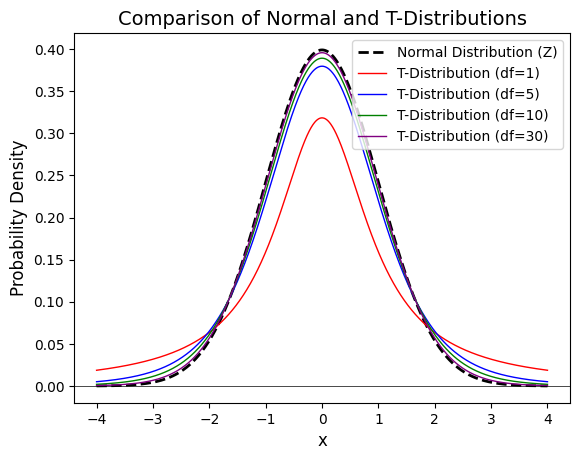

In [4]:
# Plot the Normal Distribution
plt.plot(x, norm.pdf(x), label="Normal Distribution (Z)", color="black", linestyle="--", linewidth=2)

# Plot T-Distributions with varying degrees of freedom (df)
dfs = [1, 5, 10, 30]  # Degrees of freedom
colors = ["red", "blue", "green", "purple"]

for df, color in zip(dfs, colors):
    plt.plot(x, t.pdf(x, df), label=f"T-Distribution (df={df})", color=color, linewidth=1)


# Add labels, legend, and title
plt.title("Comparison of Normal and T-Distributions", fontsize=14)
plt.xlabel("x", fontsize=12)
plt.ylabel("Probability Density", fontsize=12)
plt.axhline(0, color="black", linewidth=0.5, linestyle="-")
plt.legend()
plt.show()

### Confidence Interval Estimation with T-Statistic

When the sample size is small (n < 30) and the population standard deviation ($\sigma$) is unknown, the **t-distribution** is used instead of the z-distribution for confidence interval estimation.

**Steps**

1. **Take a Random Sample**:  
   Draw a sample of size (n = 25) from the population.

2. **Calculate Sample Statistics**:  
   Compute the **sample mean ($\bar{x}$)** and the **sample standard deviation s**.

3. **Set Confidence Level and Calculate Margin of Error**.

4. **Estimate the Confidence Interval**:  
   $$
   CI = \bar{x} \pm MOE
   $$

In [10]:
import pandas as pd
import numpy as np
import scipy.stats as stats
import seaborn as sns

# Load the Tips dataset
tips = sns.load_dataset('tips')

# Treating the tips dataset as the population
population_df = tips.copy()

# Step 1: Take a random sample from the population
n = 25  # Sample size
sample_df = population_df.sample(n=n, random_state=9)

# Step 2: Calculate the sample statistics
sample_mean = sample_df['total_bill'].mean()  # Sample mean (point estimate)
sample_std = sample_df['total_bill'].std()    # Sample standard deviation

# Step 3: Set confidence level and calculate the margin of error
confidence_level = 0.95  # 95% confidence level
df = n - 1  # Degrees of freedom

# Calculate the critical value (t-score) for 95% confidence level
t_critical = t.ppf(1 - (1 - confidence_level) / 2, df)

# Calculate Standard Error (SE)
SE = sample_std / np.sqrt(n)

# Calculate Margin of Error (MOE)
MOE = t_critical * SE

# Step 4: Calculate the confidence interval
lower_bound = sample_mean - MOE
upper_bound = sample_mean + MOE

# Display the results
print(f"Sample Mean (Point Estimate): {sample_mean:.2f}")
print(f"Sample Standard Deviation: {sample_std:.2f}")
print(f"95% Confidence Interval for Population Mean: ({lower_bound:.2f}, {upper_bound:.2f})")


Sample Mean (Point Estimate): 19.54
Sample Standard Deviation: 11.07
95% Confidence Interval for Population Mean: (14.97, 24.10)


**Results**

For a 95% confidence level:  
- **Point Estimate (Sample Mean)**: e.g., 19.25 units.  
- **Confidence Interval**: e.g., \([14.97, 24.10]\), indicating the population mean likely lies within this range.